Week 1 -Lab 0


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio

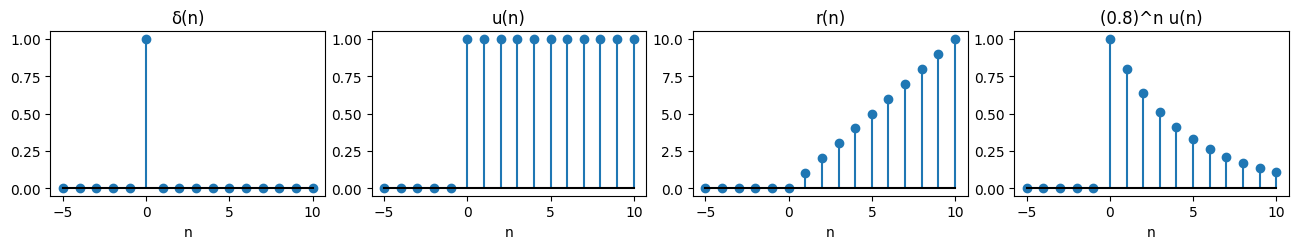

In [4]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step = (n >= 0).astype(float)       # unit step
ramp = n * step                     # unit ramp
expo = 0.8**n * step                # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
plt.tight_layout()
plt.show()

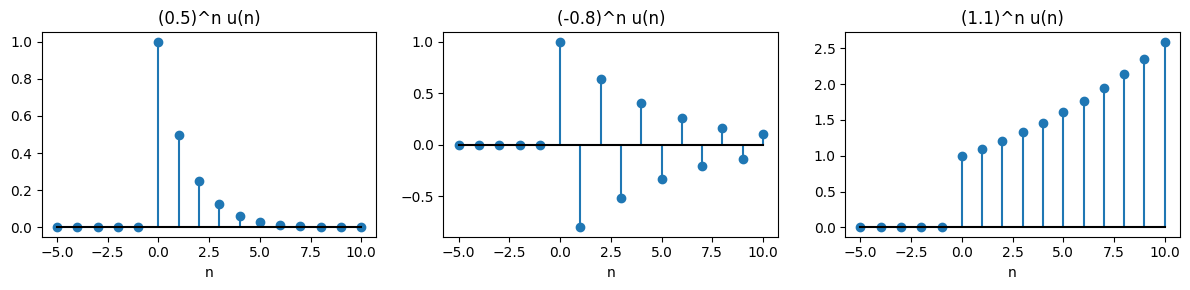

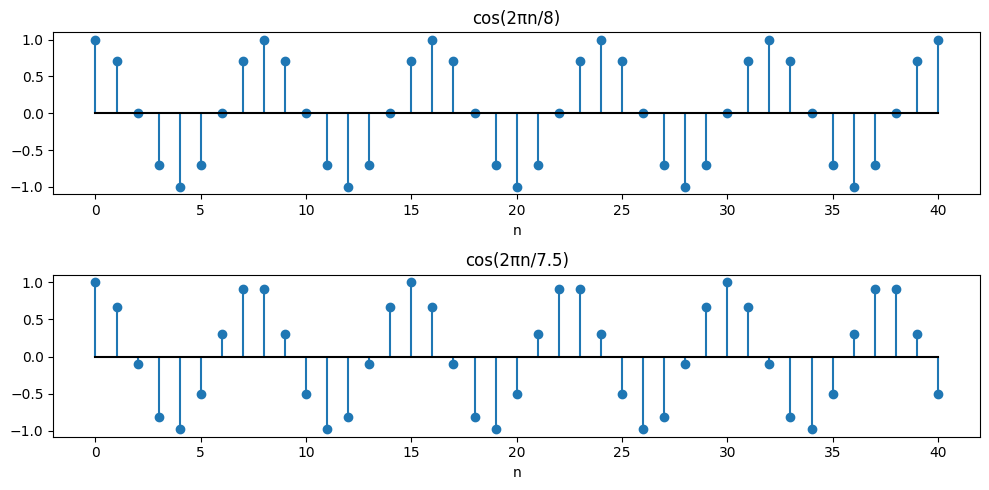

In [5]:
# Part 1: Plot (a)^n u(n) for a = 0.5, -0.8, and 1.1
n = np.arange(-5, 11)
step = (n >= 0).astype(float)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, a in zip(axes, a_values):
    x = (a**n) * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n")
plt.tight_layout()
plt.show()

# Part 2: Plot cos(2*pi*n/8) and cos(2*pi*n/7.5) for 0 <= n <= 40
n2 = np.arange(0, 41)
x1 = np.cos(2 * np.pi * n2 / 8)
x2 = np.cos(2 * np.pi * n2 / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].stem(n2, x1, basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")

axes[1].stem(n2, x2, basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")

plt.tight_layout()
plt.show()

fs = 16000 Hz, duration = 2.00 s, samples = 32000


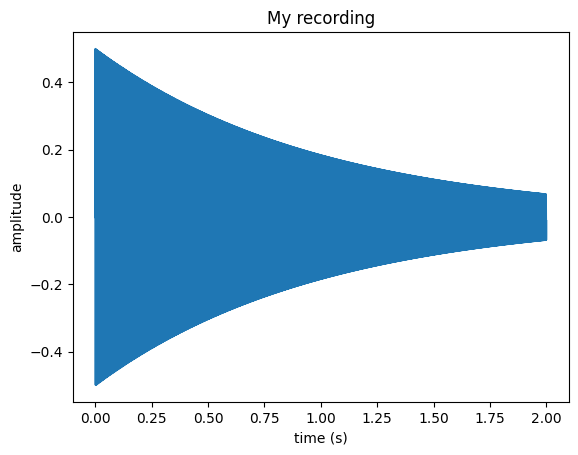

In [6]:
import os
fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)             # stereo -> mono
    x = x / np.max(np.abs(x))          # normalise to [-1, 1]
else:
    fs = 16000                         # fallback test signal
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

# Play audio in notebook
Audio(x, rate=fs)